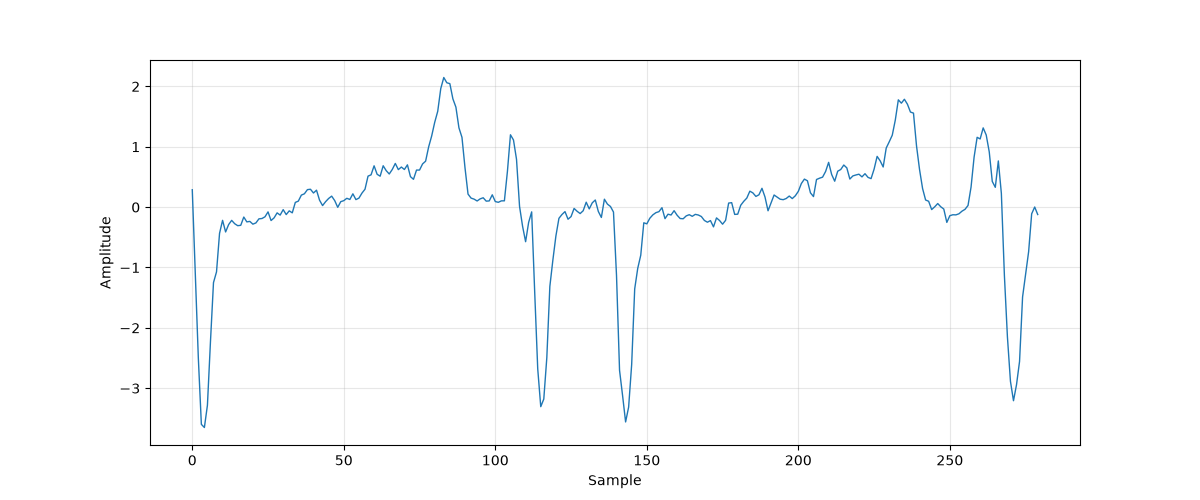

In [ ]:
%matplotlib widget

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from mpl_interactions import zoom_factory, panhandler

data = np.loadtxt("ECG5000/ECG5000_TRAIN.txt")

df = pl.DataFrame(
    data,
    schema=["label"] + [f"sample_{i}" for i in range(1, data.shape[1])],
    orient="row",
).with_columns(pl.col("label").cast(pl.Int64))

A = df.to_numpy()

# Class 1 signals, excluding the label column
signals = A[A[:, 0] == 5, 1:]

# Concatenate the first seven signals
y = signals[:2].ravel()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(np.arange(y.size), y, linewidth=1)
ax.set_xlabel("Sample")
ax.set_ylabel("Amplitude")
ax.grid(alpha=0.3)

disconnect_zoom = zoom_factory(ax)
pan = panhandler(fig, button=1)

plt.show()